# Risk inference and crowding figures


In [1]:
import matplotlib.pyplot as plt
import numpy as np

from risk_informed_planner.visualization import enable_latex

# Planner settings used by the experiment; the .npz files don't store them.
STEP_SIZE = 50                       # cfg.STEP_SIZE
DESIRED_SPEED = 3.0                  # risk_model.desired_speed
LOOKAHEAD_DISTANCE = 150.0           # risk_model.lookahead_distance
MAX_TCPA_FOR_COLLISION_RISK = 120.0  # risk_model.max_tcpa_for_collision_risk

## Notation

Symbols match the paper's `Real-time requirements` subsection.

| code | paper | meaning |
|---|---|---|
| `MAX_NODES` | $N_{\max}$ | node budget |
| `len(nodes)` | $\lvert V \rvert$ | current tree size |
| `nbrad_m` | $\ell_{\mathrm{nb}}$ | neighborhood radius |
| `A_m2` | $A$ | free area |
| `kappa` | $\kappa$ | fraction of candidate edges reaching the cost computation |
| `nbar` | $\bar{n}$ | risk samples per evaluated edge |
| `ncalls_tot` | $Q_{\mathrm{tot}}$ | risk evaluations per planning run |
| `t_r` | $t_{r}$ | wall-clock time of one risk evaluation |
| `deadline_s` | $T$ | replanning deadline |

$t_{r}$ covers evidence construction, BBN inference *and* the severity-to-cost
mapping, so it is labelled "risk evaluation" rather than "BBN call" throughout.
Its distribution has a long right tail (median 0.172 ms, mean 0.195 ms,
max 68 ms); the budget uses the *mean*, because the total planning time is
$Q_{\mathrm{tot}}\,\bar{t}_{r}$ regardless of how individual calls scatter.

## Per-evaluation cost

risk evaluations pooled : 6,804,607
mean t_r                : 0.1061 ms
median t_r              : 0.0911 ms
std. deviation          : 0.2528 ms
min / max               : 0.0713 / 227.4510 ms

  N_max | mean t_r [ms]
-------------------------
    750 |        0.1161
   1000 |        0.1169
   1250 |        0.1053
   1500 |        0.1069
   1750 |        0.1099
   2000 |        0.1097
   2250 |        0.1019
   2500 |        0.1026


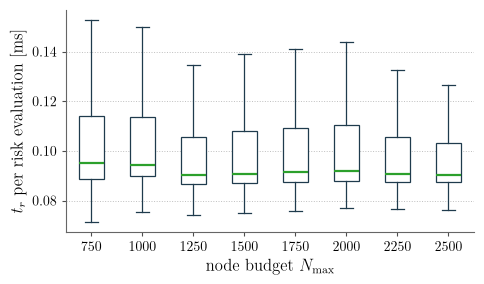

In [2]:
"""Figure: distribution of t_r against the node budget.

Sanity check -- one risk evaluation should not get more expensive because the
tree has more nodes in it, so this should be flat.
"""

import matplotlib.pyplot as plt
import numpy as np

# Discard the first WARMUP calls of each configuration: caches, allocation and
# any lazy network compilation land there and inflate the small-budget means.
WARMUP = 200

data = np.load("experiment_compute_average_risk_compute_time_stats.npz", allow_pickle=True)
risk_compute_times_by_max_nodes = data["risk_compute_times_by_max_nodes"].item()
nodes_sorted = sorted(risk_compute_times_by_max_nodes)

t_r_ms = {
    n: np.asarray(risk_compute_times_by_max_nodes[n])[WARMUP:] * 1e3
    for n in nodes_sorted
}

pooled = np.concatenate([t_r_ms[n] for n in nodes_sorted])
print(f"risk evaluations pooled : {pooled.size:,}")
print(f"mean t_r                : {pooled.mean():.4f} ms")
print(f"median t_r              : {np.median(pooled):.4f} ms")
print(f"std. deviation          : {pooled.std():.4f} ms")
print(f"min / max               : {pooled.min():.4f} / {pooled.max():.4f} ms")
print()
print(f"{'N_max':>7} | {'mean t_r [ms]':>13}")
print("-" * 25)
for n in nodes_sorted:
    print(f"{n:>7} | {t_r_ms[n].mean():>13.4f}")

INK = "#1f3b4d"
MEDIAN = "#2ca02c"

enable_latex(True)

fig, ax = plt.subplots(figsize=(5.0, 3.0))

ax.boxplot(
    [t_r_ms[n] for n in nodes_sorted],
    positions=np.arange(len(nodes_sorted)),
    widths=0.5,
    patch_artist=True,
    showfliers=False,
    zorder=3,
    boxprops=dict(facecolor="white", edgecolor=INK, linewidth=0.9),
    medianprops=dict(color=MEDIAN, linewidth=1.6),
    whiskerprops=dict(color=INK, linewidth=0.9),
    capprops=dict(color=INK, linewidth=0.9),
)

ax.set_xticks(np.arange(len(nodes_sorted)))
ax.set_xticklabels(nodes_sorted)
ax.set_xlabel(r"node budget $N_{\max}$")
ax.set_ylabel(r"$t_{r}$ per risk evaluation [ms]")

ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle=":", linewidth=0.7, color="0.75")
ax.xaxis.grid(False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("0.4")
ax.tick_params(colors="0.3", length=3)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_color("black")

fig.tight_layout()
fig.savefig("risk_compute_time_per_call_vs_nodes.png", bbox_inches="tight", dpi=300)
fig.savefig("risk_compute_time_per_call_vs_nodes.pdf", bbox_inches="tight")
plt.show()

## Real-time budget

Evaluates the budget inequality

$$ t_{r} \;\le\; \frac{T \, A}{\kappa \, \bar{n} \, \pi \ell_{\mathrm{nb}}^{2} N_{\max}^{2}}
        \;=\; \frac{T}{Q_{\mathrm{tot}}(N_{\max})} , $$

using the *measured* $Q_{\mathrm{tot}}$ so that $\kappa$ and $\bar{n}$ need not
be guessed. Since $Q_{\mathrm{tot}} \propto N_{\max}^{2}$ while $t_{r}$ is flat,
the ceiling falls quadratically and the two cross at the largest budget that
meets the deadline.

Two candidate deadlines are printed:

* `segment` -- $\eta / v_{\mathrm{d}}$, the time to traverse one planner
  segment, i.e. how long before the vessel commits to the next one;
* `sensing` -- $\min\{t_{\mathrm{CPA}}, d_{\mathrm{look}} / v_{\mathrm{d}}\}$.

`segment` is the tighter and more defensible of the two, since
$d_{\mathrm{look}}$ is a perception horizon rather than a control time
constant. Set `DEADLINE_MODE` to match whichever the paper states.

> **Note.** The sweep, like the crowding run, uses `RISK_CUTOFF = np.inf`,
> so the measured $Q_{\mathrm{tot}}$ excludes the risk gate. A finite
> $r_{\mathrm{cut}}$ can only reject edges, so these counts bound the gated
> planner from above.

In [3]:
"""Fit Q_tot(N_max), pick the deadline, and locate the crossing."""

import numpy as np

DEADLINE_MODE = "segment"   # "segment" or "sensing"
WARMUP = 200

data = np.load("experiment_compute_average_risk_compute_time_stats.npz", allow_pickle=True)
risk_compute_times_by_max_nodes = data["risk_compute_times_by_max_nodes"].item()
ncalls_by_max_nodes = data["ncalls_by_max_nodes"].item()
nodes_sorted = sorted(ncalls_by_max_nodes)

# --- geometry, independent of N_max (saved by the crowding run) ---
crowding = np.load("experiment_crowding_stats.npz")
nbrad_m = float(crowding["nbrad_m"])
A_m2 = float(crowding["A_m2"])

# --- deadline ---
segment_s = STEP_SIZE / DESIRED_SPEED
sensing_s = min(MAX_TCPA_FOR_COLLISION_RISK, LOOKAHEAD_DISTANCE / DESIRED_SPEED)
deadline_s = segment_s if DEADLINE_MODE == "segment" else sensing_s

# --- measured quantities ---
xs = np.asarray(nodes_sorted, float)
ncalls = np.asarray([np.mean(ncalls_by_max_nodes[n]) for n in nodes_sorted], float)
t_r_ms = np.asarray(
    [np.mean(np.asarray(risk_compute_times_by_max_nodes[n])[WARMUP:]) * 1e3
     for n in nodes_sorted], float
)
t_r_bar = float(t_r_ms.mean())

# --- Q_tot = c * N_max^2, least squares through the origin ---
c_quad = float(np.sum(ncalls * xs**2) / np.sum(xs**4))
kappa_nbar = c_quad * A_m2 / (np.pi * nbrad_m**2)

# --- crossing: T / (c N^2) = t_r  =>  N = sqrt(T / (c t_r)) ---
n_cross = float(np.sqrt((deadline_s * 1e3) / (c_quad * t_r_bar)))

budget_ms = (deadline_s * 1e3) / ncalls

print(f"deadline mode : {DEADLINE_MODE}")
print(f"  segment  eta/v_d              = {segment_s:.0f} s")
print(f"  sensing  min(tcpa, dlook/v_d) = {sensing_s:.0f} s")
print(f"  -> T = {deadline_s:.0f} s")
print()
print(f"ell_nb = {nbrad_m:.0f} m,  A = {A_m2:,.0f} m^2")
print(f"Q_tot(N) ~ {c_quad:.5f} * N^2   =>  kappa*nbar = {kappa_nbar:.3f}")
print(f"mean t_r = {t_r_bar:.4f} ms  (first {WARMUP} calls per config dropped)")
print()
header = f"{'N_max':>7} | {'Q_tot':>10} | {'t_r [ms]':>9} | {'budget [ms]':>11} | {'ratio':>6}"
print(header)
print("-" * len(header))
for n, cc, tm, bm in zip(nodes_sorted, ncalls, t_r_ms, budget_ms):
    print(f"{n:>7} | {cc:>10,.0f} | {tm:>9.4f} | {bm:>11.4f} | {tm / bm:>5.2f}x")
print()
print(f"-> budget and measured t_r cross at N_max = {n_cross:.0f}")

deadline mode : segment
  segment  eta/v_d              = 17 s
  sensing  min(tcpa, dlook/v_d) = 50 s
  -> T = 17 s

ell_nb = 150 m,  A = 769,152 m^2
Q_tot(N) ~ 0.05706 * N^2   =>  kappa*nbar = 0.621
mean t_r = 0.1087 ms  (first 200 calls per config dropped)

  N_max |      Q_tot |  t_r [ms] | budget [ms] |  ratio
-------------------------------------------------------
    750 |     32,417 |    0.1161 |      0.5141 |  0.23x
   1000 |     58,749 |    0.1169 |      0.2837 |  0.41x
   1250 |     91,128 |    0.1053 |      0.1829 |  0.58x
   1500 |    128,319 |    0.1069 |      0.1299 |  0.82x
   1750 |    178,254 |    0.1099 |      0.0935 |  1.18x
   2000 |    232,430 |    0.1097 |      0.0717 |  1.53x
   2250 |    287,280 |    0.1019 |      0.0580 |  1.76x
   2500 |    352,664 |    0.1026 |      0.0473 |  2.17x

-> budget and measured t_r cross at N_max = 1640


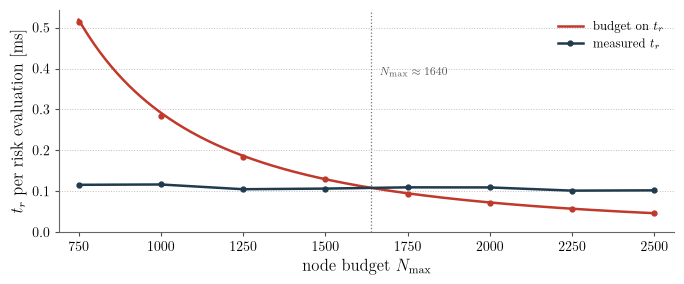

In [4]:
"""Figure: measured t_r against the budget ceiling."""

import matplotlib.pyplot as plt
import numpy as np

MEASURED = "#1f3b4d"
BUDGET = "#c0392b"

enable_latex(True)

fig, ax = plt.subplots(figsize=(7.0, 3.0))

# Smooth ceiling from the fitted Q_tot, so the quadratic fall is visible
# rather than implied by eight straight segments.
grid = np.linspace(xs.min(), xs.max(), 300)
ax.plot(grid, (deadline_s * 1e3) / (c_quad * grid**2),
        color=BUDGET, lw=1.8, label=r"budget on $t_{r}$")
ax.plot(xs, budget_ms, ls="none", marker="o", markersize=3.5, color=BUDGET)

ax.plot(xs, t_r_ms, color=MEASURED, lw=1.8, marker="o", markersize=3.5,
        label=r"measured $t_{r}$")

# Mark the crossing explicitly -- the region where the curves separate is too
# thin to read as a shaded band.
if xs.min() <= n_cross <= xs.max():
    ax.axvline(n_cross, color="0.45", lw=0.9, ls=":", zorder=1)
    ax.annotate(
        rf"$N_{{\max}} \approx {n_cross:.0f}$",
        xy=(n_cross, ax.get_ylim()[1] * 0.72),
        xytext=(6, 0), textcoords="offset points",
        fontsize=8, color="0.35", ha="left", va="center",
    )

ax.set_xlabel(r"node budget $N_{\max}$")
ax.set_ylabel(r"$t_{r}$ per risk evaluation [ms]")
ax.set_ylim(bottom=0)
ax.set_xlim(xs.min() - 60, xs.max() + 60)

ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle=":", linewidth=0.7, color="0.75")
ax.xaxis.grid(False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("0.4")
ax.tick_params(colors="0.3", length=3)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_color("black")

ax.legend(frameon=False, loc="upper right", fontsize=9)

fig.tight_layout()
fig.savefig("risk_compute_time_budget_vs_measured.png", bbox_inches="tight", dpi=300)
fig.savefig("risk_compute_time_budget_vs_measured.pdf", bbox_inches="tight")
plt.show()

## Crowding: neighborhood size and total risk evaluations

Validates Eq.~(nbrs) and Eq.~(total) against a single run, and measures the two
constants the paper needs.

The expected neighborhood size under uniform sampling is

$$\bar{m} = \frac{\pi \ell_{\mathrm{nb}}^2}{A} \, |V| ,$$

so the number of risk evaluations spent per node added should grow *linearly*
in the tree size $|V|$, and the cumulative count quadratically.

A single run to the largest budget traces the whole $|V|$ range, so this does
not need the sweep. Three instrumented quantities:

* `k_count`  -- size of each radius query, i.e. measured $\bar{m}$;
* `s_samples` -- risk samples per edge, i.e. measured $\bar{n}$;
* `c_calls`  -- cumulative `risk_evaluations`, sampled once per iteration.

From these, $\kappa$ falls out as the ratio between the observed cost per node
and $2\,\bar{n}\,\bar{m}$.

> **Note.** This notebook runs with `RISK_CUTOFF = np.inf`, so the cutoff gate
> never rejects an edge. The $\kappa$ measured here reflects the collision
> check, the turn limit and the parentless-neighbor skip only. Re-run with the
> finite cutoff used in the results if the paper quotes both.

In [5]:
"""Reduce the traces to kappa, nbar, and the two curves for the figure."""

import numpy as np

d = np.load("experiment_crowding_stats.npz")
k_tree, k_count = d["k_tree"], d["k_count"]
s_samples = d["s_samples"]
c_tree, c_calls = d["c_tree"], d["c_calls"]
nbrad_m, A_m2 = float(d["nbrad_m"]), float(d["A_m2"])


def binned_mean(x, y, n_bins=24, min_count=5):
    """Mean of y over equal-width bins in x. Drops sparse bins."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    edges = np.linspace(x.min(), x.max(), n_bins + 1)
    idx = np.clip(np.digitize(x, edges) - 1, 0, n_bins - 1)
    xs, ys = [], []
    for b in range(n_bins):
        m = idx == b
        if m.sum() >= min_count:
            xs.append(x[m].mean())
            ys.append(y[m].mean())
    return np.asarray(xs), np.asarray(ys)


# --- panel A: measured vs predicted neighborhood size ---
kx, ky = binned_mean(k_tree, k_count)
pred_k = lambda v: np.pi * nbrad_m**2 * np.asarray(v, float) / A_m2

# --- panel B: risk evaluations spent per node added ---
# Runs are concatenated in c_tree, so split where |V| resets.
splits = np.flatnonzero(np.diff(c_tree) < 0) + 1
rate_x, rate_y = [], []
for seg_t, seg_c in zip(np.split(c_tree, splits), np.split(c_calls, splits)):
    dv, dc = np.diff(seg_t), np.diff(seg_c)
    ok = dv > 0
    rate_x.append(seg_t[1:][ok])
    rate_y.append(dc[ok] / dv[ok])
rate_x, rate_y = np.concatenate(rate_x), np.concatenate(rate_y)
rx, ry = binned_mean(rate_x, rate_y)

# --- the two constants ---
nbar = float(s_samples.mean())

# Least-squares slope through the origin of (cost per node) vs |V|.
slope = float(np.sum(rate_x * rate_y) / np.sum(rate_x**2))
kappa = slope * A_m2 / (2.0 * nbar * np.pi * nbrad_m**2)

# Boundary deficit: how far the measured neighborhood falls below the
# interior-point prediction, which is an upper bound.
deficit = float(np.mean(ky / pred_k(kx)))

print(f"nbar   (risk samples per edge)     = {nbar:.2f}")
print(f"kappa  (fraction reaching cost)    = {kappa:.3f}")
print(f"        of which boundary clipping = {deficit:.3f} of the predicted |N|")
print(f"        so kappa net of geometry   = {kappa / deficit:.3f}")
print()
print(f"cost per node = {slope:.4f} * |V|   [risk evaluations]")
print(f"=> ncalls_tot(N) ~ {slope / 2:.4f} * N^2")

# Eq. (total) from the independent constants, interior-point geometry.
kappa_net = kappa / deficit
c_pred = kappa_net * nbar * np.pi * nbrad_m**2 / A_m2
print(f"=> Eq. (total) predicts Q_tot ~ {c_pred:.4f} * N^2 (kappa = {kappa_net:.3f}, nbar = {nbar:.2f})")
for n in (1000, 2500, 5000):
    print(f"     N = {n:>5}:  {slope / 2 * n**2:>12,.0f} evaluations")

nbar   (risk samples per edge)     = 3.63
kappa  (fraction reaching cost)    = 0.169
        of which boundary clipping = 0.837 of the predicted |N|
        so kappa net of geometry   = 0.202

cost per node = 0.1127 * |V|   [risk evaluations]
=> ncalls_tot(N) ~ 0.0563 * N^2
=> Eq. (total) predicts Q_tot ~ 0.0673 * N^2 (kappa = 0.202, nbar = 3.63)
     N =  1000:        56,348 evaluations
     N =  2500:       352,173 evaluations
     N =  5000:     1,408,691 evaluations


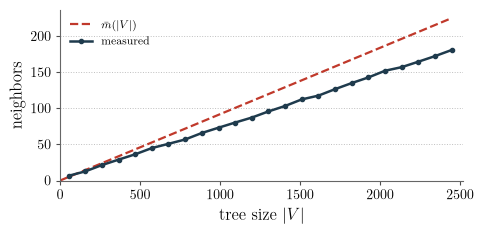

In [6]:
"""Figure: neighborhood size against the tree size, within one run."""

import matplotlib.pyplot as plt
import numpy as np

INK = "#1f3b4d"
PRED = "#c0392b"
DEADLINE = "0.45"

enable_latex(True)


def style_axes(ax):
    ax.set_ylim(bottom=0)
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, linestyle=":", linewidth=0.7, color="0.75")
    ax.xaxis.grid(False)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("0.4")
    ax.tick_params(colors="0.3", length=3)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_color("black")


fig, ax = plt.subplots(figsize=(5.0, 2.5))

vs = np.linspace(1, kx.max(), 200)
ax.plot(vs, pred_k(vs), color=PRED, lw=1.6, ls="--",
        label=r"$\bar{m}(|V|)$")
ax.plot(kx, ky, color=INK, lw=1.8, marker="o", markersize=3.0,
        label="measured")
ax.set_xlabel(r"tree size $|V|$")
ax.set_ylabel("neighbors")
ax.set_xlim(0, kx.max() * 1.03)
ax.legend(frameon=False, loc="upper left", fontsize=8)
style_axes(ax)

fig.tight_layout()
fig.savefig("crowding_neighbors.png", bbox_inches="tight", dpi=300)
fig.savefig("crowding_neighbors.pdf", bbox_inches="tight")
plt.show()


T / t_r = 153,382 evaluations, crossed at N_max = 1640
fitted Q_tot ~ 0.0571 * N^2, runs per budget = 5


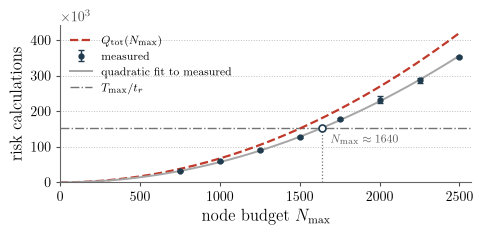

In [7]:
"""Figure: total risk evaluations per run against the node budget."""

import matplotlib.pyplot as plt
import numpy as np

# Per-run totals from the N_max sweep.
sweep = np.load("experiment_compute_average_risk_compute_time_stats.npz", allow_pickle=True)
q_by_n = sweep["ncalls_by_max_nodes"].item()
q_nodes = np.asarray(sorted(q_by_n), float)
q_runs = [np.asarray(q_by_n[n], float) for n in sorted(q_by_n)]
q_mean = np.asarray([r.mean() for r in q_runs])
q_lo = q_mean - np.asarray([r.min() for r in q_runs])
q_hi = np.asarray([r.max() for r in q_runs]) - q_mean
c_fit = float(np.sum(q_mean * q_nodes**2) / np.sum(q_nodes**4))

# Deadline in evaluations: T / mean t_r (deadline_s, t_r_bar from the
# budget cell). The quadratic fit crosses it at the largest budget that
# fits, the same N_max as the budget figure.
q_deadline = deadline_s * 1e3 / t_r_bar
n_fit = float(np.sqrt(q_deadline / c_fit))
print(f"T / t_r = {q_deadline:,.0f} evaluations, crossed at N_max = {n_fit:.0f}")
print(f"fitted Q_tot ~ {c_fit:.4f} * N^2, runs per budget = {len(q_runs[0])}")

FIT = "0.65"

fig, ax = plt.subplots(figsize=(5.0, 2.5))

vs = np.linspace(1, q_nodes.max(), 200)
ax.plot(vs, c_pred * vs**2, color=PRED, lw=1.6, ls="--",
        label=r"$Q_{\mathrm{tot}}(N_{\max})$")
ax.plot(vs, c_fit * vs**2, color=FIT, lw=1.4, ls="-", zorder=2,
        label="quadratic fit to measured")
ax.errorbar(q_nodes, q_mean, yerr=[q_lo, q_hi], color=INK, lw=0,
            elinewidth=1.0, capsize=2.0, marker="o", markersize=3.5,
            label="measured")
ax.axhline(q_deadline, color=DEADLINE, lw=1.0, ls="-.", zorder=1,
           label=r"$T_{\mathrm{max}} / t_{r}$")
ax.vlines(n_fit, 0, q_deadline, color=DEADLINE, lw=0.9, ls=":",
          zorder=1)
ax.plot(n_fit, q_deadline, marker="o", markersize=5.0,
        markerfacecolor="white", markeredgecolor=INK,
        markeredgewidth=1.2, zorder=4)
ax.annotate(rf"$N_{{\max}} \approx {n_fit:.0f}$",
            xy=(n_fit, q_deadline), xytext=(6, -5),
            textcoords="offset points", fontsize=8, color="0.35",
            ha="left", va="top")

ax.set_xlabel(r"node budget $N_{\max}$")
ax.set_ylabel("risk calculations")
ax.set_xlim(0, q_nodes.max() * 1.03)
ax.ticklabel_format(axis="y", style="sci", scilimits=(3, 3))
# Legend order: model, measured, fit, deadline.
handles, labels = ax.get_legend_handles_labels()
order = [labels.index(l) for l in (
    r"$Q_{\mathrm{tot}}(N_{\max})$", "measured",
    "quadratic fit to measured", r"$T_{\mathrm{max}} / t_{r}$")]
ax.legend([handles[i] for i in order], [labels[i] for i in order],
          frameon=False, loc="upper left", fontsize=8)
style_axes(ax)

fig.tight_layout()
fig.savefig("crowding_risk_calculations.png", bbox_inches="tight", dpi=300)
fig.savefig("crowding_risk_calculations.pdf", bbox_inches="tight")
plt.show()
